<a href="https://colab.research.google.com/github/Khan-Md-Shakil/Machine_Learning_A_To_Z_Practices-/blob/main/Clustering_Techniques_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [90]:
# Install necessary libraries
!pip install -q -U matplotlib seaborn pandas scikit-learn

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Load the Mall Customer Segmentation dataset
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/datasets/Mall_Customers.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Data Preprocessing and Exploration

In [91]:
# Show the first few rows of the dataset
df.head()

# Explore the dataset - check for missing values and basic info
df.info()

# Selecting relevant columns for clustering (Annual Income and Spending Score)
df = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Check for null values
df.isnull().sum()



<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

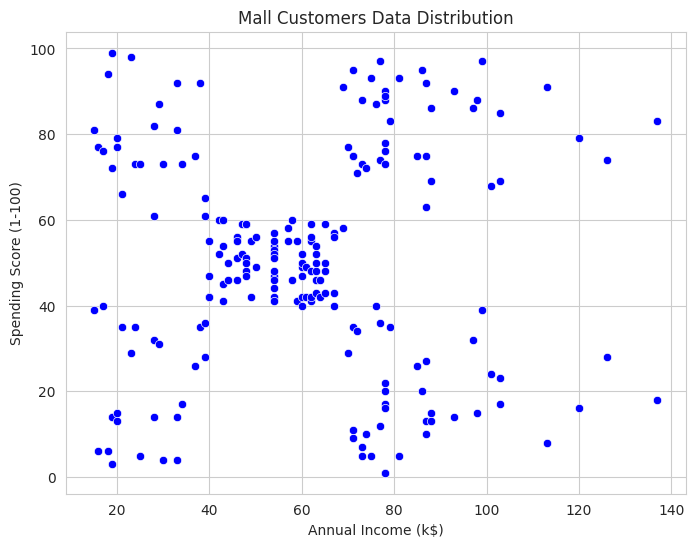

In [92]:
# Standardize the data (important for K-Means)
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

# Visualize the data distribution
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df['Annual Income (k$)'], y=df['Spending Score (1-100)'], color='blue')
plt.title('Mall Customers Data Distribution')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

# K-means clustering

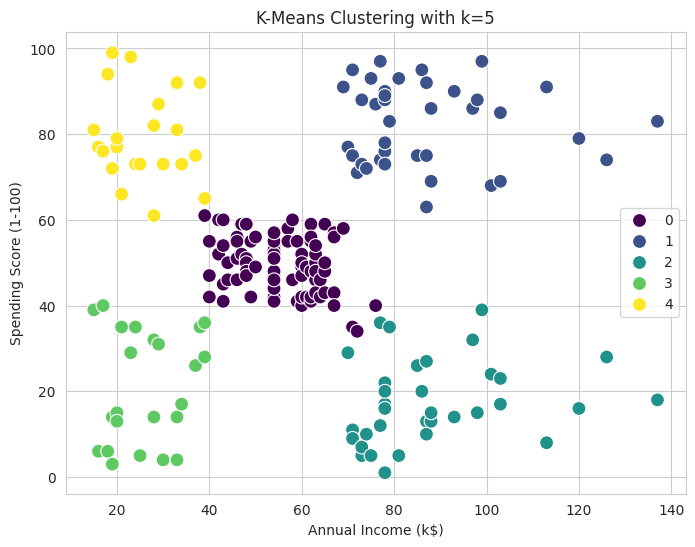

In [93]:
# --- K-Means Clustering ---
from sklearn.cluster import KMeans
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, random_state=20)
kmeans.fit(df_scaled)

# Visualize the K-Means clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df['Annual Income (k$)'], y=df['Spending Score (1-100)'], hue=kmeans.labels_, palette='viridis', s=100)
plt.title(f'K-Means Clustering with k={optimal_k}')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

# Hierarchical Clustering

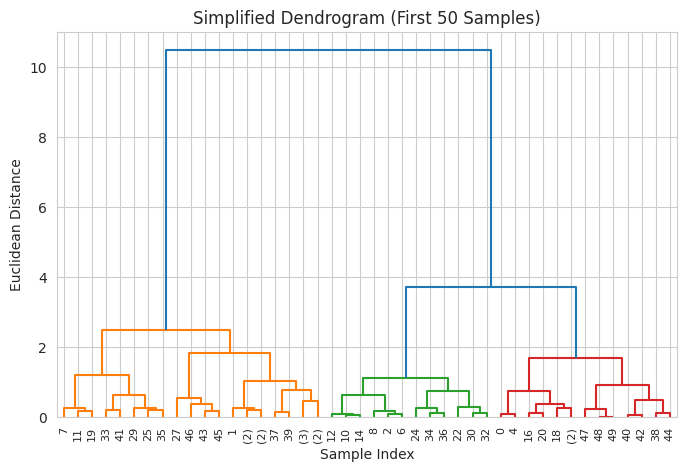

In [94]:
# --- Hierarchical Clustering (Simplified Dendrogram) ---
# Use a subset of the data to keep visualization readable
from scipy.cluster.hierarchy import dendrogram, linkage
sample_data = df_scaled[:50]  # taking first 50 samples

# Create linkage matrix
linked = linkage(sample_data, method='ward')

# Plot the simplified dendrogram
plt.figure(figsize=(8, 5))
dendrogram(
    linked,
    truncate_mode='level',  # show only top levels of the tree
    p=5,                    # show last 5 merges
    color_threshold=3
)
plt.title('Simplified Dendrogram (First 50 Samples)')
plt.xlabel('Sample Index')
plt.ylabel('Euclidean Distance')
plt.show()


# Comparison between K-means and Hierarchical

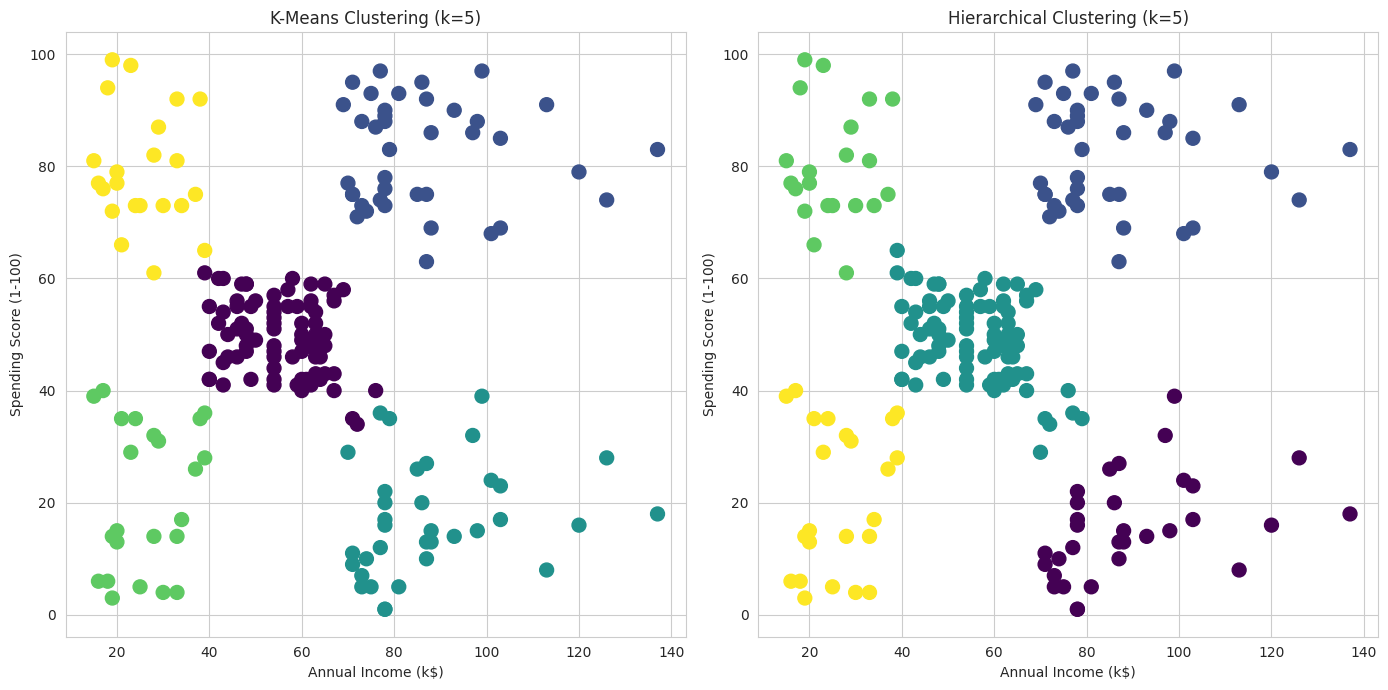

In [95]:
# Apply Agglomerative Clustering (Hierarchical) with k=5
from sklearn.cluster import AgglomerativeClustering
hierarchical = AgglomerativeClustering(n_clusters=5, linkage='ward')
y_hc = hierarchical.fit_predict(df_scaled)

# Plot the comparison of K-Means and Hierarchical Clustering
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

# K-Means plot
ax1.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], c=kmeans.labels_, cmap='viridis', s=100)
ax1.set_title(f'K-Means Clustering (k={optimal_k})')
ax1.set_xlabel('Annual Income (k$)')
ax1.set_ylabel('Spending Score (1-100)')

# Hierarchical plot
ax2.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], c=y_hc, cmap='viridis', s=100)
ax2.set_title('Hierarchical Clustering (k=5)')
ax2.set_xlabel('Annual Income (k$)')
ax2.set_ylabel('Spending Score (1-100)')

plt.tight_layout()
plt.show()

# Assignment

1. Load and Preprocess the Data:

Load the Socio-Economic Factors and Income Dataset.

Clean the data by handling missing values.

Encode the Education Level (categorical feature).

Standardize the numerical features (Age and Income) to ensure fair clustering.

2. Apply K-Means Clustering:

Use K-Means to segment the data into 5 clusters based on Age, Income, and Education Level.

Visualize the resulting clusters using a scatter plot of Income vs. Age, with color coding for the clusters.

Identify and interpret the characteristics of each cluster.

3. Apply Hierarchical Clustering:

Use Hierarchical Clustering (Agglomerative) with 5 clusters.

Visualize the dendrogram to understand the hierarchy of the clusters.

Compare the Hierarchical Clustering results with K-Means.

# **Library Install & Import**

In [96]:
# Install necessary libraries
!pip install -q -U matplotlib seaborn pandas scikit-learn scipy

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')
# Display settings
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

# **Load the Dataset**

In [97]:
# Load the Socio-Economic Factors and Income Dataset
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/datasets/sgdata.csv')

# Show first few rows
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,ID,Sex,Marital status,Age,Education,Income,Occupation,Settlement size
0,100000001,0,single,67,university,124670,skilled employee / official,2
1,100000002,1,non-single (divorced / separated / married / w...,22,high school,150773,skilled employee / official,2
2,100000003,0,single,49,high school,89210,unemployed / unskilled,0
3,100000004,0,single,45,high school,171565,skilled employee / official,1
4,100000005,0,single,53,high school,149031,skilled employee / official,1


# **Explore the Dataset**

In [98]:
# Basic info
print("Shape:", df.shape)
print("\n--- Info ---")
df.info()

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Statistical Summary ---")
df.describe()

Shape: (2000, 8)

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   ID               2000 non-null   int64
 1   Sex              2000 non-null   int64
 2   Marital status   2000 non-null   str  
 3   Age              2000 non-null   int64
 4   Education        2000 non-null   str  
 5   Income           2000 non-null   int64
 6   Occupation       2000 non-null   str  
 7   Settlement size  2000 non-null   int64
dtypes: int64(5), str(3)
memory usage: 263.7 KB

--- Missing Values ---
ID                 0
Sex                0
Marital status     0
Age                0
Education          0
Income             0
Occupation         0
Settlement size    0
dtype: int64

--- Statistical Summary ---


,ID,Sex,Age,Income,Settlement size
count,2.000000e+03,2000.000000,2000.000000,2000.000000,2000.000000
mean,1.000010e+08,0.457000,35.909000,120954.419000,0.739000
std,5.774946e+02,0.498272,11.719402,38108.824679,0.812533
min,1.000000e+08,0.000000,18.000000,35832.000000,0.000000
25%,1.000005e+08,0.000000,27.000000,97663.250000,0.000000
50%,1.000010e+08,0.000000,33.000000,115548.500000,1.000000
75%,1.000015e+08,1.000000,42.000000,138072.250000,1.000000
max,1.000020e+08,1.000000,76.000000,309364.000000,2.000000


# **Data Cleaning — Handle Missing Values**

In [99]:
# Check duplicates
print("Duplicate rows:", df.duplicated().sum())

# Drop duplicates if any
df = df.drop_duplicates()

# Handle missing values
# Numerical columns -> fill with median
num_cols = df.select_dtypes(include=[np.number]).columns
for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# Categorical columns -> fill with mode
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum())

Duplicate rows: 0
Missing values after cleaning:
ID                 0
Sex                0
Marital status     0
Age                0
Education          0
Income             0
Occupation         0
Settlement size    0
dtype: int64


# **Encode Education Level (Categorical Feature)**

In [100]:
# Education is categorical — encode it
le = LabelEncoder()
df['Education_Encoded'] = le.fit_transform(df['Education'])

# Show mapping
print("Education Encoding Mapping:")
for i, cls in enumerate(le.classes_):
    print(f"  {cls} -> {i}")

df[['Education', 'Education_Encoded']].head()

Education Encoding Mapping:
  graduate school -> 0
  high school -> 1
  other / unknown -> 2
  university -> 3


,Education,Education_Encoded
0,university,3
1,high school,1
2,high school,1
3,high school,1
4,high school,1


# **Select Features & Standardize**

In [101]:
# Features for clustering: Age, Income, Education
features = ['Age', 'Income', 'Education_Encoded']
X = df[features].copy()

# Standardize the numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Feature matrix shape:", X_scaled.shape)
print("Mean after scaling:", np.round(X_scaled.mean(axis=0), 4))
print("Std after scaling :", np.round(X_scaled.std(axis=0), 4))

Feature matrix shape: (2000, 3)
Mean after scaling: [ 0.  0. -0.]
Std after scaling : [1. 1. 1.]


# **Apply K-Means Clustering (k=5)**

In [102]:
# --- K-Means Clustering ---
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# Add cluster labels to dataframe
df['KMeans_Cluster'] = kmeans.labels_

print("Cluster counts:")
print(df['KMeans_Cluster'].value_counts().sort_index())

Cluster counts:
KMeans_Cluster
0    877
1     72
2    524
3    256
4    271
Name: count, dtype: int64


# **Visualize K-Means Clusters (Income vs Age)**

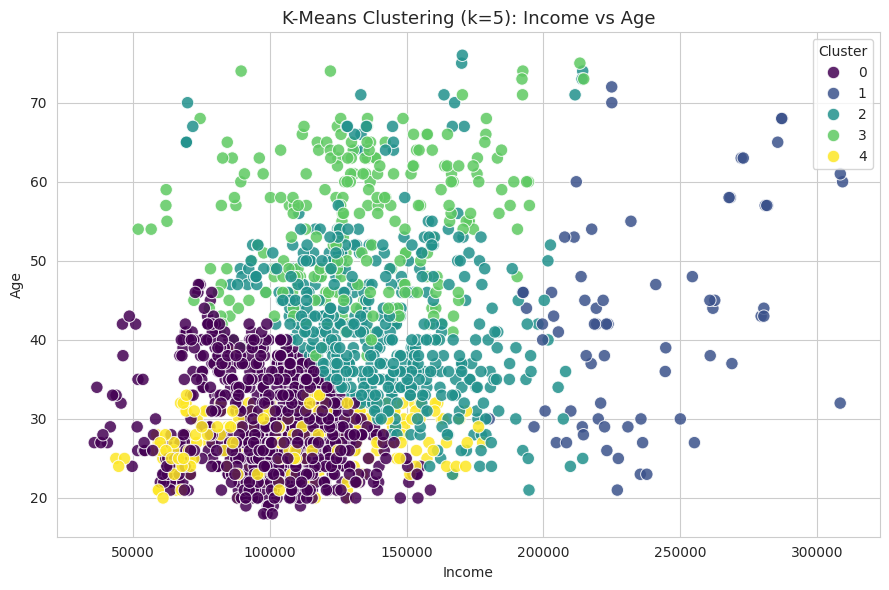

In [103]:
# Scatter plot of Income vs Age with cluster colors
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=df['Income'], y=df['Age'],
    hue=df['KMeans_Cluster'], palette='viridis', s=80, alpha=0.85
)
plt.title('K-Means Clustering (k=5): Income vs Age', fontsize=13)
plt.xlabel('Income')
plt.ylabel('Age')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

# **Interpret Each Cluster (Characteristics)**

In [104]:
# Cluster characteristics — mean values of each cluster
cluster_summary = df.groupby('KMeans_Cluster').agg(
    Count=('ID', 'count'),
    Avg_Age=('Age', 'mean'),
    Avg_Income=('Income', 'mean'),
    Avg_Education=('Education_Encoded', 'mean'),
    Dominant_Education=('Education', lambda x: x.mode()[0]),
    Dominant_Occupation=('Occupation', lambda x: x.mode()[0])
).round(2)

print("Cluster Characteristics:")
cluster_summary

Cluster Characteristics:


,Count,Avg_Age,Avg_Income,Avg_Education,Dominant_Education,Dominant_Occupation
KMeans_Cluster,,,,,,
0,877,29.29,100090.79,1.00,high school,skilled employee / official
1,72,42.89,236618.69,2.18,university,management / self-employed / highly qualified ...
2,524,41.50,140992.95,0.94,high school,skilled employee / official
3,256,54.18,132288.28,3.00,university,skilled employee / official
4,271,27.41,108289.91,2.00,other / unknown,skilled employee / official


# **Hierarchical Clustering — Dendrogram**

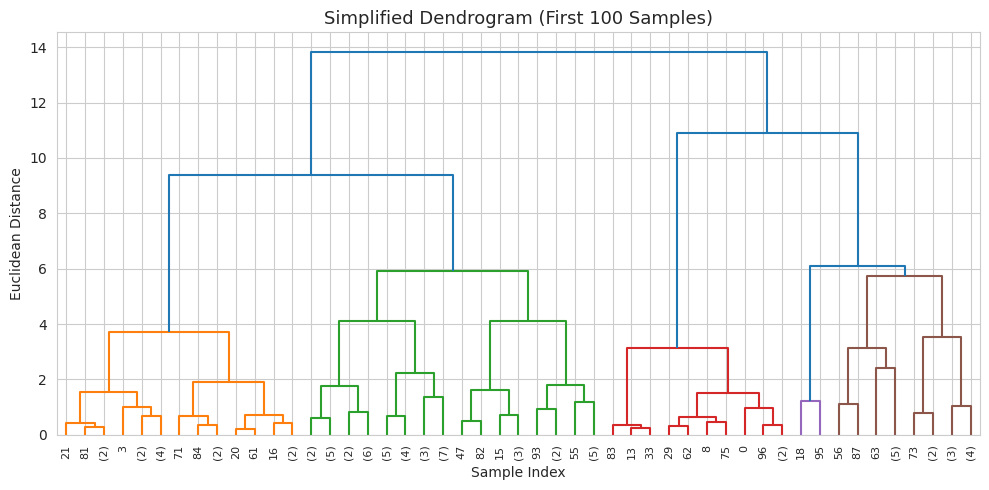

In [105]:
# --- Hierarchical Clustering (Dendrogram) ---
# Use a sample for readable dendrogram
sample_data = X_scaled[:100]

linked = linkage(sample_data, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(
    linked,
    truncate_mode='level',
    p=5,
    color_threshold=6
)
plt.title('Simplified Dendrogram (First 100 Samples)', fontsize=13)
plt.xlabel('Sample Index')
plt.ylabel('Euclidean Distance')
plt.tight_layout()
plt.show()

# **Apply Agglomerative Clustering (k=5)**

In [106]:
# --- Agglomerative (Hierarchical) Clustering ---
hierarchical = AgglomerativeClustering(n_clusters=5, linkage='ward')
df['Hier_Cluster'] = hierarchical.fit_predict(X_scaled)

print("Hierarchical cluster counts:")
print(df['Hier_Cluster'].value_counts().sort_index())

Hierarchical cluster counts:
Hier_Cluster
0    291
1    346
2    833
3    271
4    259
Name: count, dtype: int64


# **Compare K-Means vs Hierarchical (Side-by-Side)**

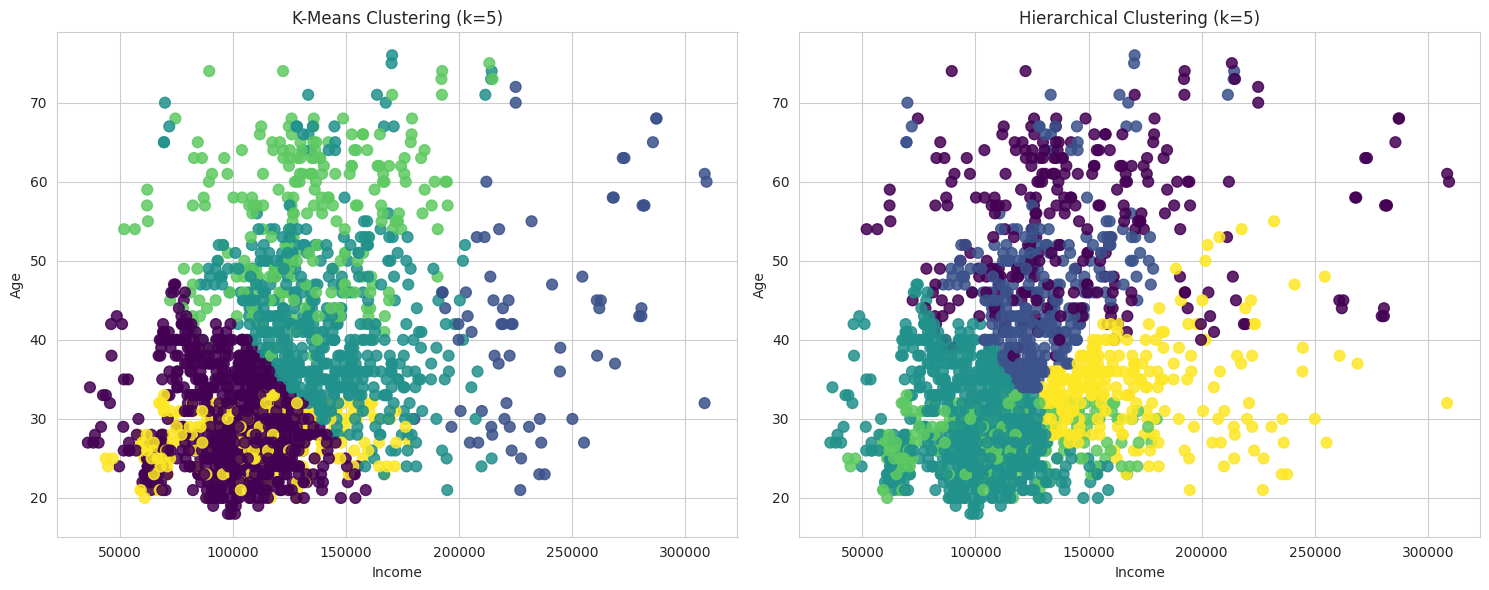

In [107]:
# Comparison plot: K-Means vs Hierarchical
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# K-Means plot
ax1.scatter(df['Income'], df['Age'], c=df['KMeans_Cluster'], cmap='viridis', s=60, alpha=0.85)
ax1.set_title(f'K-Means Clustering (k={optimal_k})', fontsize=12)
ax1.set_xlabel('Income')
ax1.set_ylabel('Age')

# Hierarchical plot
ax2.scatter(df['Income'], df['Age'], c=df['Hier_Cluster'], cmap='viridis', s=60, alpha=0.85)
ax2.set_title('Hierarchical Clustering (k=5)', fontsize=12)
ax2.set_xlabel('Income')
ax2.set_ylabel('Age')

plt.tight_layout()
plt.show()

# **Quantitative Comparison (Cross-tab)**

In [108]:
# Cross-tabulation to compare how labels match between the two methods
ct = pd.crosstab(df['KMeans_Cluster'], df['Hier_Cluster'])
print("Cross-tab: K-Means (rows) vs Hierarchical (columns)")
ct

Cross-tab: K-Means (rows) vs Hierarchical (columns)


Hier_Cluster,0,1,2,3,4
KMeans_Cluster,,,,,
0,0,29,831,0,17
1,34,0,0,1,37
2,0,317,2,0,205
3,256,0,0,0,0
4,1,0,0,270,0


# **Final Summary & Interpretation**

In [109]:
print("=" * 70)
print("FINAL COMPARISON SUMMARY")
print("=" * 70)

print("\n--- K-Means Cluster Characteristics ---")
print(cluster_summary)

print("\n--- Hierarchical Cluster Characteristics ---")
hier_summary = df.groupby('Hier_Cluster').agg(
    Count=('ID', 'count'),
    Avg_Age=('Age', 'mean'),
    Avg_Income=('Income', 'mean'),
    Avg_Education=('Education_Encoded', 'mean'),
    Dominant_Education=('Education', lambda x: x.mode()[0])
).round(2)
print(hier_summary)

print("\n--- Observations ---")
print("""
1. K-Means partitions the data into 5 groups based on Age, Income, and Education.
2. Hierarchical (Ward linkage) also produces 5 clusters.
3. The cross-tab shows how similarly (or differently) the two methods group the data.
4. If cross-tab is roughly diagonal, both methods agree strongly.
5. K-Means is faster & scalable; Hierarchical gives a tree (dendrogram) showing hierarchy.
""")

FINAL COMPARISON SUMMARY

--- K-Means Cluster Characteristics ---
                Count  Avg_Age  Avg_Income  Avg_Education Dominant_Education  \
KMeans_Cluster                                                                 
0                 877    29.29   100090.79           1.00        high school   
1                  72    42.89   236618.69           2.18         university   
2                 524    41.50   140992.95           0.94        high school   
3                 256    54.18   132288.28           3.00         university   
4                 271    27.41   108289.91           2.00    other / unknown   

                                              Dominant_Occupation  
KMeans_Cluster                                                     
0                                     skilled employee / official  
1               management / self-employed / highly qualified ...  
2                                     skilled employee / official  
3                                

# **Thank You**